# 서울의 이동을 읽다

### 따릉이 · 버스 · 지하철, 2025년의 하루하루

**B3-1 · 실제 공개자료 기반 시계열 분석**

이 노트북은 제출용 Python 모듈을 직접 실행해 표와 그래프를 만든다. 원본 26개에서 검증한 일별 집계본을 사용하며 API 키나 추가 다운로드는 필요하지 않다.

**읽는 순서:** 데이터와 품질 → 요일별 차이 → 월별 변화 → 평소와 다른 날짜 → 검증과 해석의 한계.

> 단위는 따릉이 **대여 건수**, 버스·지하철 **승차 건수**다. 고유 이용자 수가 아니며, 지하철에는 서울 밖 역도 포함된다.

In [1]:
import json
import sys
import tempfile
from pathlib import Path

import pandas as pd
from IPython.display import HTML, Image, Markdown, display
from pandas.testing import assert_frame_equal

# JupyterLab을 B3-1 또는 저장소 루트에서 열어도 동일하게 찾는다.
ROOT = Path.cwd()
if not (ROOT / "data/sources.json").exists():
    ROOT = ROOT / "B3-1"
assert (ROOT / "data/sources.json").exists(), "B3-1 또는 저장소 루트에서 실행하세요."

sys.path.insert(0, str(ROOT))
from transport_analysis.clean import clean_observations
from transport_analysis.io import read_aggregates
from transport_analysis.metrics import summarize
from transport_analysis.plots import make_plots
from transport_analysis.report import render_report

raw_daily, sources = read_aggregates(ROOT / "data")
data, quality = clean_observations(raw_daily)
stats, features = summarize(data)
saved_stats = json.loads((ROOT / "outputs/statistics.json").read_text())
assert stats == saved_stats, "노트북 계산과 제출 통계가 다릅니다."
manifest = json.loads((ROOT / "data/processed/manifest.json").read_text())
NAMES = {"bike": "따릉이", "bus": "서울버스", "subway": "공개 지하철"}
print(f"Python {sys.version.split()[0]} · pandas {pd.__version__}")
print("공식 일별 집계본 해시 검증 및 재계산 완료 / 제출 통계와 전 항목 일치")

Python 3.13.1 · pandas 3.0.6
공식 일별 집계본 해시 검증 및 재계산 완료 / 제출 통계와 전 항목 일치


In [2]:
display(
    HTML("""
<style>
.b3-cards {display:grid;grid-template-columns:repeat(auto-fit,minmax(150px,1fr));gap:14px;margin:20px 0 30px;}
.b3-card {padding:22px;border:1px solid #dce6ed;border-radius:16px;background:#f5f9fc;}
.b3-card strong {display:block;font-size:29px;line-height:1.5;color:#123954;}
.b3-card span {font-size:13px;color:#526777;}
.b3-note {padding:17px 21px;background:#eff8f6;border-left:4px solid #149d8d;border-radius:0 12px 12px 0;line-height:1.8;}
</style>
""")
)
source_rows = sum(s["raw_rows"] for s in sources["sources"])
cards = [
    ("관측 기간", "365일"),
    ("비교 데이터", f"{len(data):,}행"),
    ("공식 원본", f"{len(sources['sources'])}개"),
    ("원본 관측 행", f"{source_rows:,}"),
]
display(
    HTML(
        '<div class="b3-cards">'
        + "".join(
            f'<div class="b3-card"><span>{label}</span><strong>{value}</strong></div>'
            for label, value in cards
        )
        + "</div>"
    )
)

## 1. 어떤 데이터인가?

2025-01-01부터 2025-12-31까지 같은 날짜로 정렬했다. 아래 표는 **실제 정제 데이터의 첫 10일**이다. 세 수단을 합산해 사람 수로 해석하지 않는다.

In [3]:
preview = data.pivot(index="date", columns="mode", values="value").rename(columns=NAMES)
preview.index = preview.index.strftime("%Y-%m-%d")
preview.index.name = "이용일"
display(preview.head(10).style.format("{:,.0f}").set_caption("첫 10일 · 단위: 대여/승차 건수"))

source_table = (
    pd.DataFrame(sources["sources"])
    .groupby("mode")
    .agg(원본파일=("file", "count"), 원본행=("raw_rows", "sum"), 관측일=("days", "sum"))
    .rename(index=NAMES)
)
display(source_table.style.format("{:,.0f}").set_caption("공식 원본 → 수단별 365일"))

mode,따릉이,서울버스,공개 지하철
이용일,,,
2025-01-01,"48,645","2,358,007","3,204,425"
2025-01-02,"77,718","4,718,270","7,224,979"
2025-01-03,"77,053","4,888,069","7,620,278"
2025-01-04,"56,597","3,509,345","5,499,672"
2025-01-05,"19,712","2,757,639","3,926,346"
2025-01-06,"62,525","4,830,008","7,359,852"
2025-01-07,"68,411","4,846,159","7,385,420"
2025-01-08,"66,720","4,851,851","7,362,889"
2025-01-09,"47,971","4,575,599","6,941,048"


,원본파일,원본행,관측일
mode,,,
따릉이,2,365,365
서울버스,12,"14,940,136",365
공개 지하철,12,"225,232",365


### 품질 확인

잘못된 날짜·값·중복·누락은 오류로 처리한다. 결측을 0으로 채우지 않는다. IQR 기준의 극값은 탐색 대상으로만 표시하고 자동 삭제하지 않는다. 실제 데이터에 없는 결측·이상치를 일부러 만들지 않았다.

In [4]:
quality_table = pd.DataFrame(
    {
        "항목": ["날짜 누락", "값 결측", "날짜·수단 중복", "음수", "임의 보간", "제거"],
        "건수": [
            quality[k]
            for k in [
                "missing_dates",
                "missing_values",
                "duplicate_keys",
                "negative_values",
                "imputed_rows",
                "removed_rows",
            ]
        ],
    }
)
display(quality_table.style.hide(axis="index"))

summary = pd.DataFrame(
    [
        {
            "수단": NAMES[mode],
            "관측일": s["count"],
            "연간 합계": s["total"],
            "하루 평균": s["average"],
            "주말 증감률(%)": s["weekend_change_pct"],
            "월 최고/최저(배)": s["monthly_peak_trough_ratio"],
        }
        for mode, s in stats["modes"].items()
    ]
).set_index("수단")
display(
    summary.style.format(
        {
            "관측일": "{:,.0f}",
            "연간 합계": "{:,.0f}",
            "하루 평균": "{:,.1f}",
            "주말 증감률(%)": "{:+.2f}",
            "월 최고/최저(배)": "{:.2f}",
        }
    ).set_caption("수단별 규모와 변화 · 각 수단의 합계는 별도로 해석")
)

항목,건수
날짜 누락,0
값 결측,0
날짜·수단 중복,0
음수,0
임의 보간,0
제거,0


,관측일,연간 합계,하루 평균,주말 증감률(%),월 최고/최저(배)
수단,,,,,
따릉이,365,"37,373,092","102,392.0",-23.29,2.44
서울버스,365,"1,693,606,333","4,640,017.4",-30.97,1.26
공개 지하철,365,"2,551,201,462","6,989,593.0",-31.49,1.23


## 2. 일별 흐름: 반복되는 변화가 보이는가?

얇은 선은 일별 값, 굵은 선은 **7일 이동평균**이다. 처음 6일은 연속 7일이 모이지 않아 이동평균이 비어 있다. 패널마다 세로축이 다르므로 높이를 직접 비교하지 않는다.

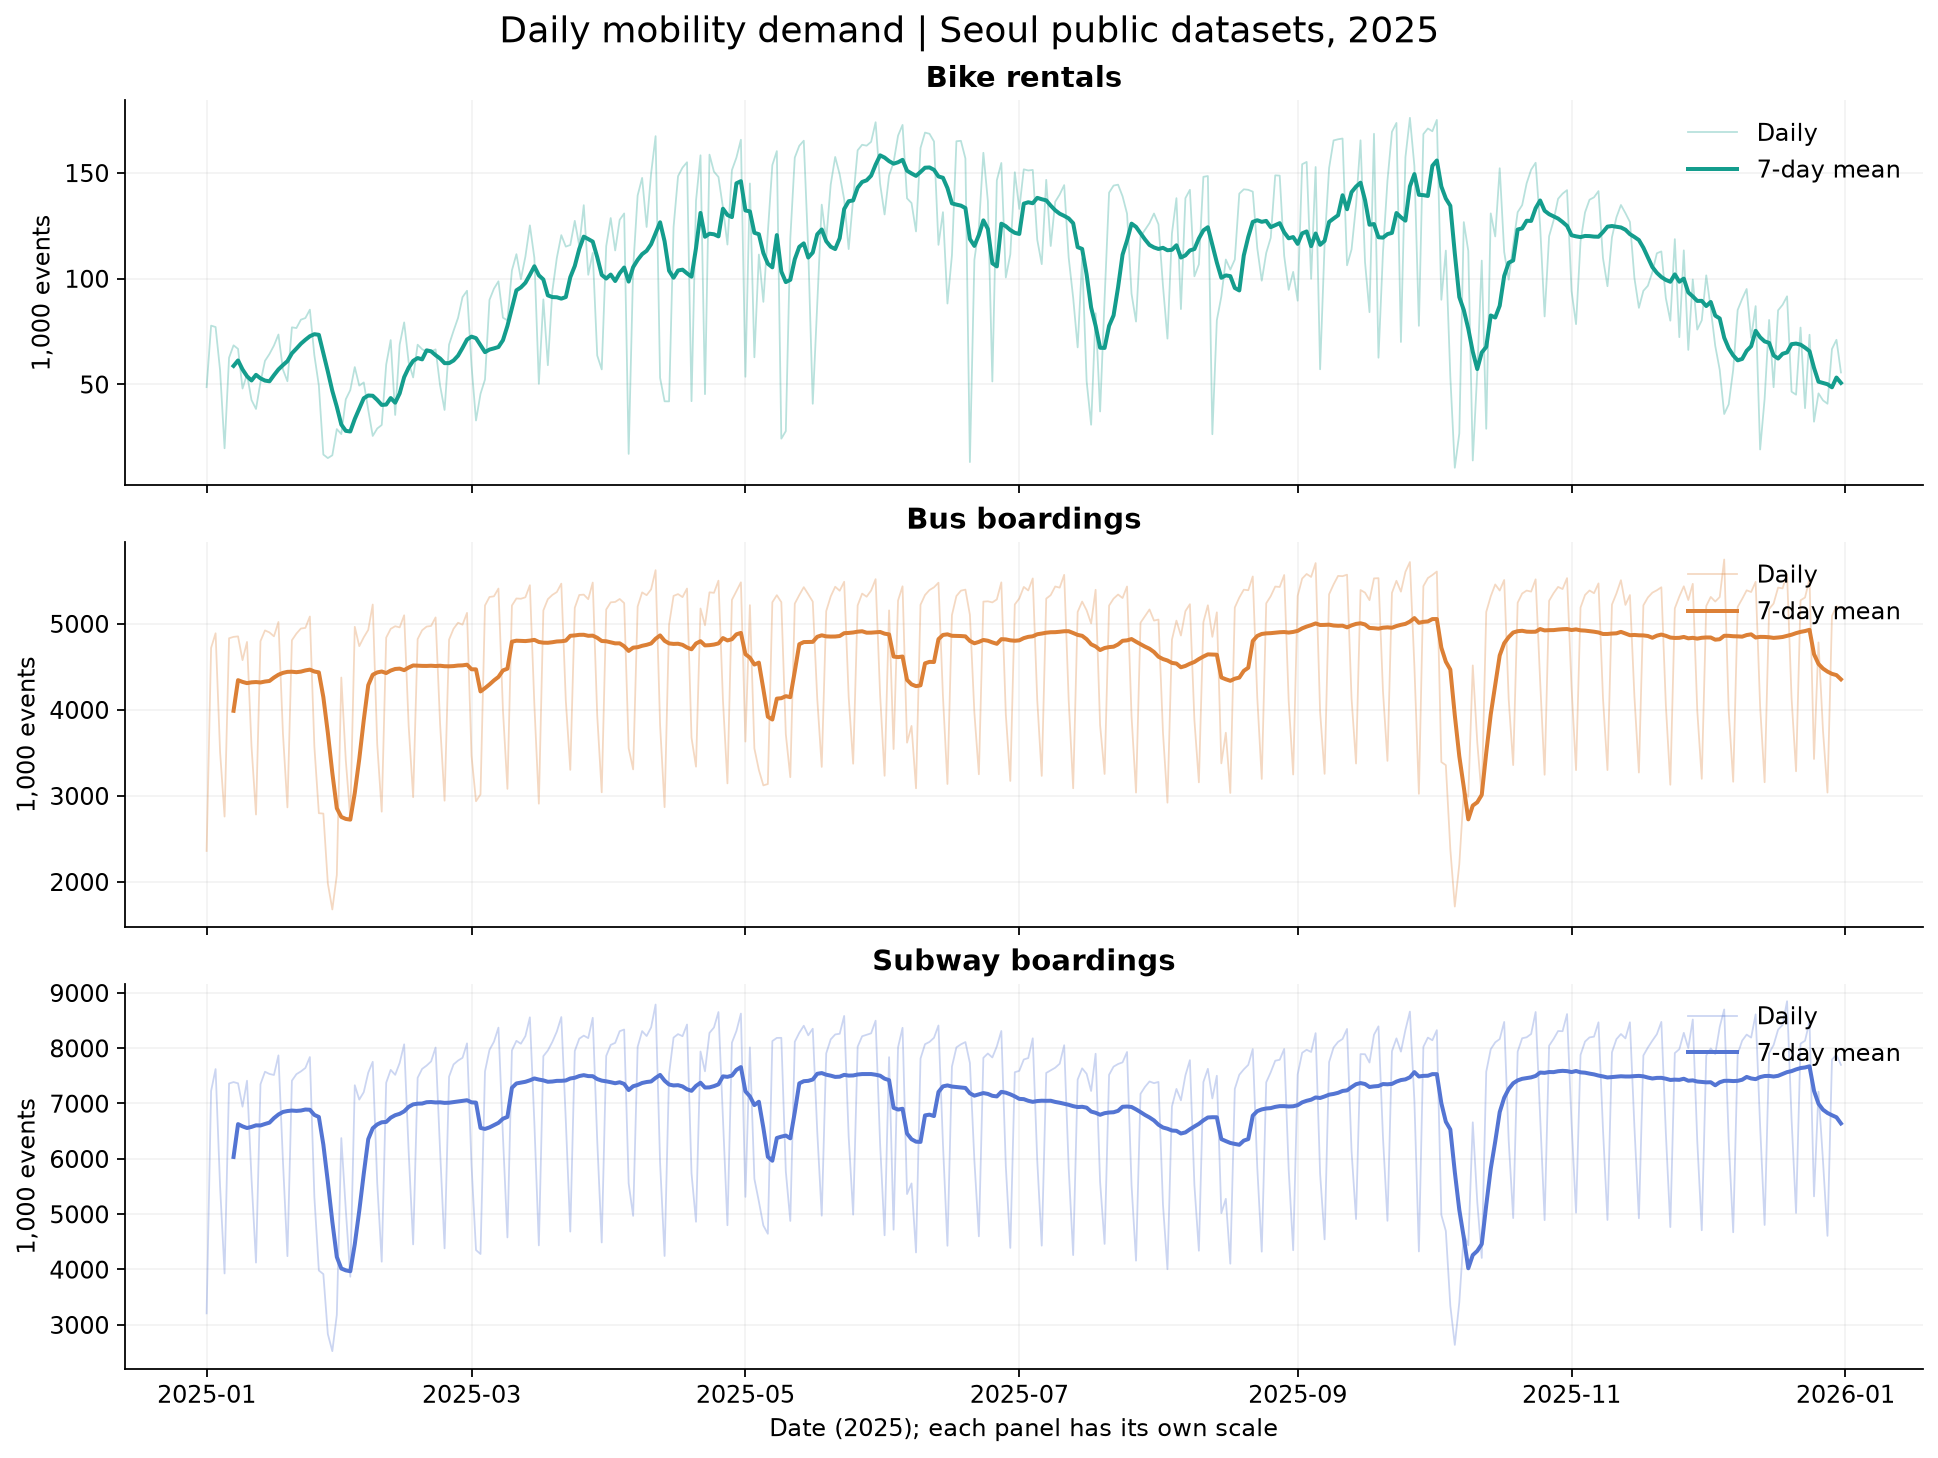

In [5]:
# 표와 동일하게 재계산한 값으로 그림도 직접 생성한다.
FIGURES = Path(tempfile.mkdtemp(prefix="b3-notebook-figures-"))
figure_names = make_plots(features, stats, FIGURES)
assert len(figure_names) == 4
display(Image(filename=str(FIGURES / "01_daily_trends.png")))

## 3. 질문 1 · 평일과 주말은 얼마나 다른가?

월~금과 토·일의 일평균을 비교한다. 공휴일은 달력 요일에 그대로 포함되므로, 이 차이가 곧 통근량의 차이라는 뜻은 아니다.

,평일 일평균,주말 일평균,평일 대비 주말(%)
수단,,,
따릉이,"109,668.4","84,131.0",-23.29
서울버스,"5,089,088.2","3,513,022.1",-30.97
공개 지하철,"7,678,456.6","5,260,810.5",-31.49


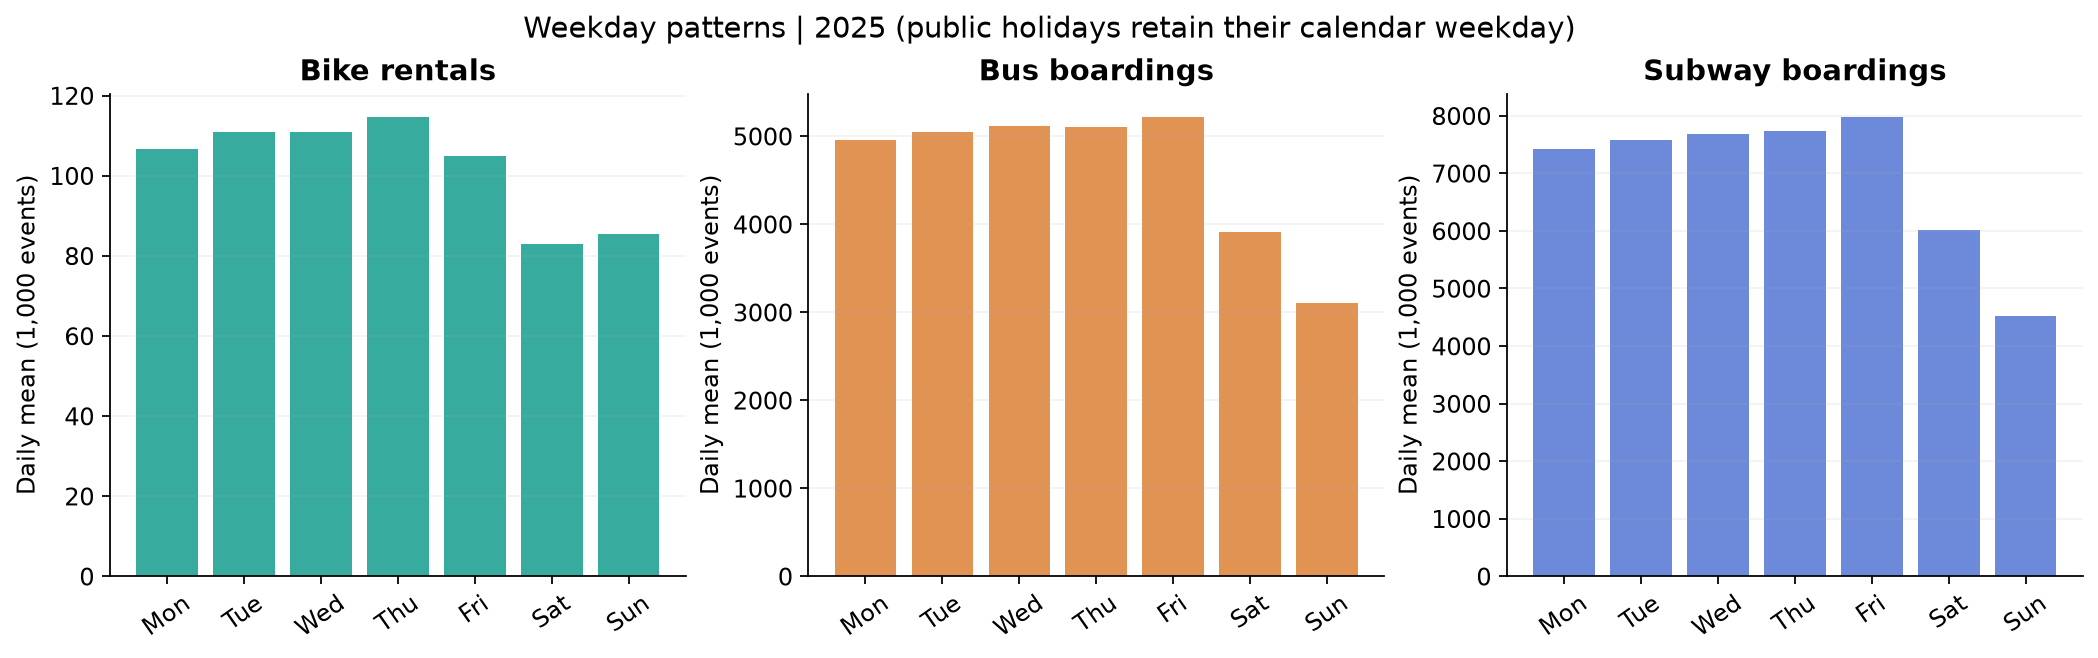

In [6]:
weekday_table = pd.DataFrame(
    [
        {
            "수단": NAMES[mode],
            "평일 일평균": s["weekday_average"],
            "주말 일평균": s["weekend_average"],
            "평일 대비 주말(%)": s["weekend_change_pct"],
        }
        for mode, s in stats["modes"].items()
    ]
).set_index("수단")
display(
    weekday_table.style.format(
        {"평일 일평균": "{:,.1f}", "주말 일평균": "{:,.1f}", "평일 대비 주말(%)": "{:+.2f}"}
    ).background_gradient(subset=["평일 대비 주말(%)"], cmap="Blues_r")
)
display(Image(filename=str(FIGURES / "02_weekday_patterns.png")))

## 4. 질문 2 · 어느 수단의 월별 변화가 큰가?

달마다 날짜 수가 달라 **월 합계 대신 하루 평균**을 쓴다. 아래 색상 표와 그래프의 100은 **각 수단의 연평균**이다. 다른 수단과의 비중을 뜻하지 않는다.

,1월,2월,3월,4월,5월,6월,7월,8월,9월,10월,11월,12월
따릉이,53.7,56.8,90.6,118.2,121.6,131.0,111.4,112.1,130.0,107.4,103.8,61.9
서울버스,85.9,96.4,100.1,103.9,100.1,100.3,104.3,99.2,108.2,95.3,103.1,103.4
공개 지하철,86.7,98.3,102.2,106.7,102.3,99.2,99.5,94.1,105.6,95.3,105.0,105.6


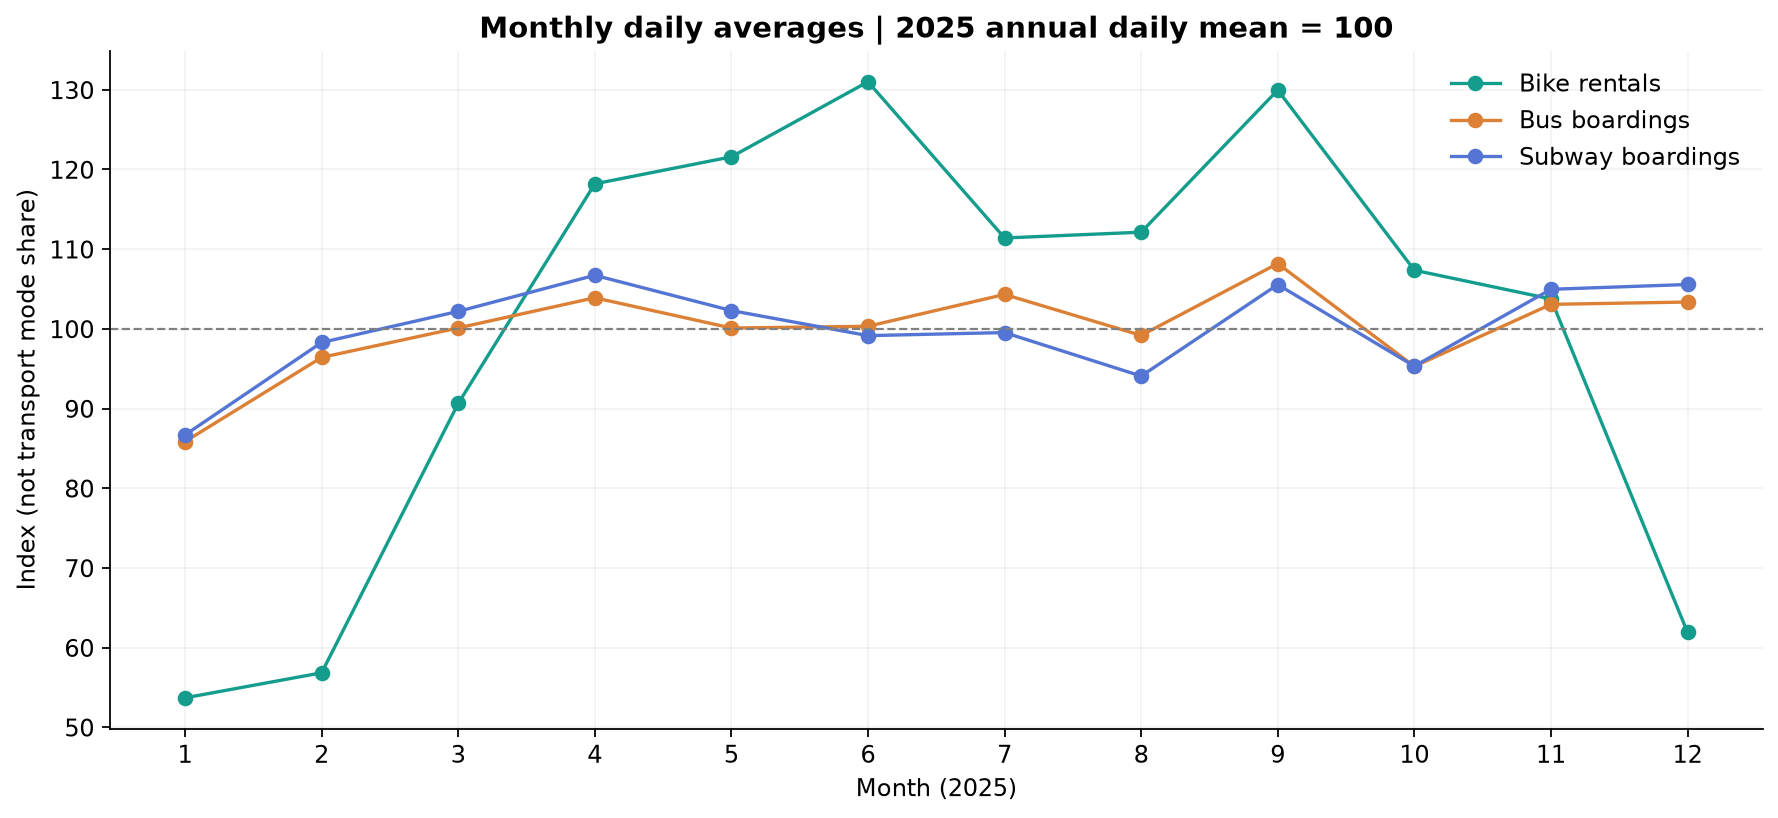

In [7]:
monthly_index = pd.DataFrame(
    {
        NAMES[mode]: {
            f"{month}월": value / s["average"] * 100
            for month, value in s["monthly_daily_means"].items()
        }
        for mode, s in stats["modes"].items()
    }
).T
display(
    monthly_index.style.format("{:.1f}")
    .background_gradient(cmap="YlGnBu", axis=None)
    .set_caption("월별 일평균 지수 · 각 수단의 연평균=100")
)
display(Image(filename=str(FIGURES / "03_monthly_patterns.png")))

## 5. 질문 3 · 평소와 다른 날짜는 언제인가?

같은 **월·요일의 평균**을 기준으로 비교한다. 절대 편차 30% 이상은 개별 수단의 탐색 후보이며, 세 수단 공동 감소는 별도로 각각 -20% 이하인 날짜를 찾는다. 두 기준을 구분한다.

이 계산은 해당 날짜도 비교 평균에 넣는 **사후 탐색**이다. 원인이나 통계적 유의성을 증명하는 방식은 아니다.

수단,날짜,실제 건수,월×요일 평균,편차(%)
따릉이,2025-04-26,"133,576","61,411.0",+117.51
따릉이,2025-06-20,"13,179","105,412.5",-87.50
따릉이,2025-10-10,"13,940","102,602.0",-86.41
서울버스,2025-10-06,"1,710,929","4,339,064.0",-60.57
서울버스,2025-01-29,"1,677,391","3,745,625.8",-55.22
서울버스,2025-01-28,"1,980,245","4,157,929.5",-52.37
공개 지하철,2025-10-06,"2,634,043","6,546,247.8",-59.76
공개 지하철,2025-01-29,"2,521,061","5,639,758.4",-55.30
공개 지하철,2025-01-28,"2,830,312","6,329,078.5",-55.28


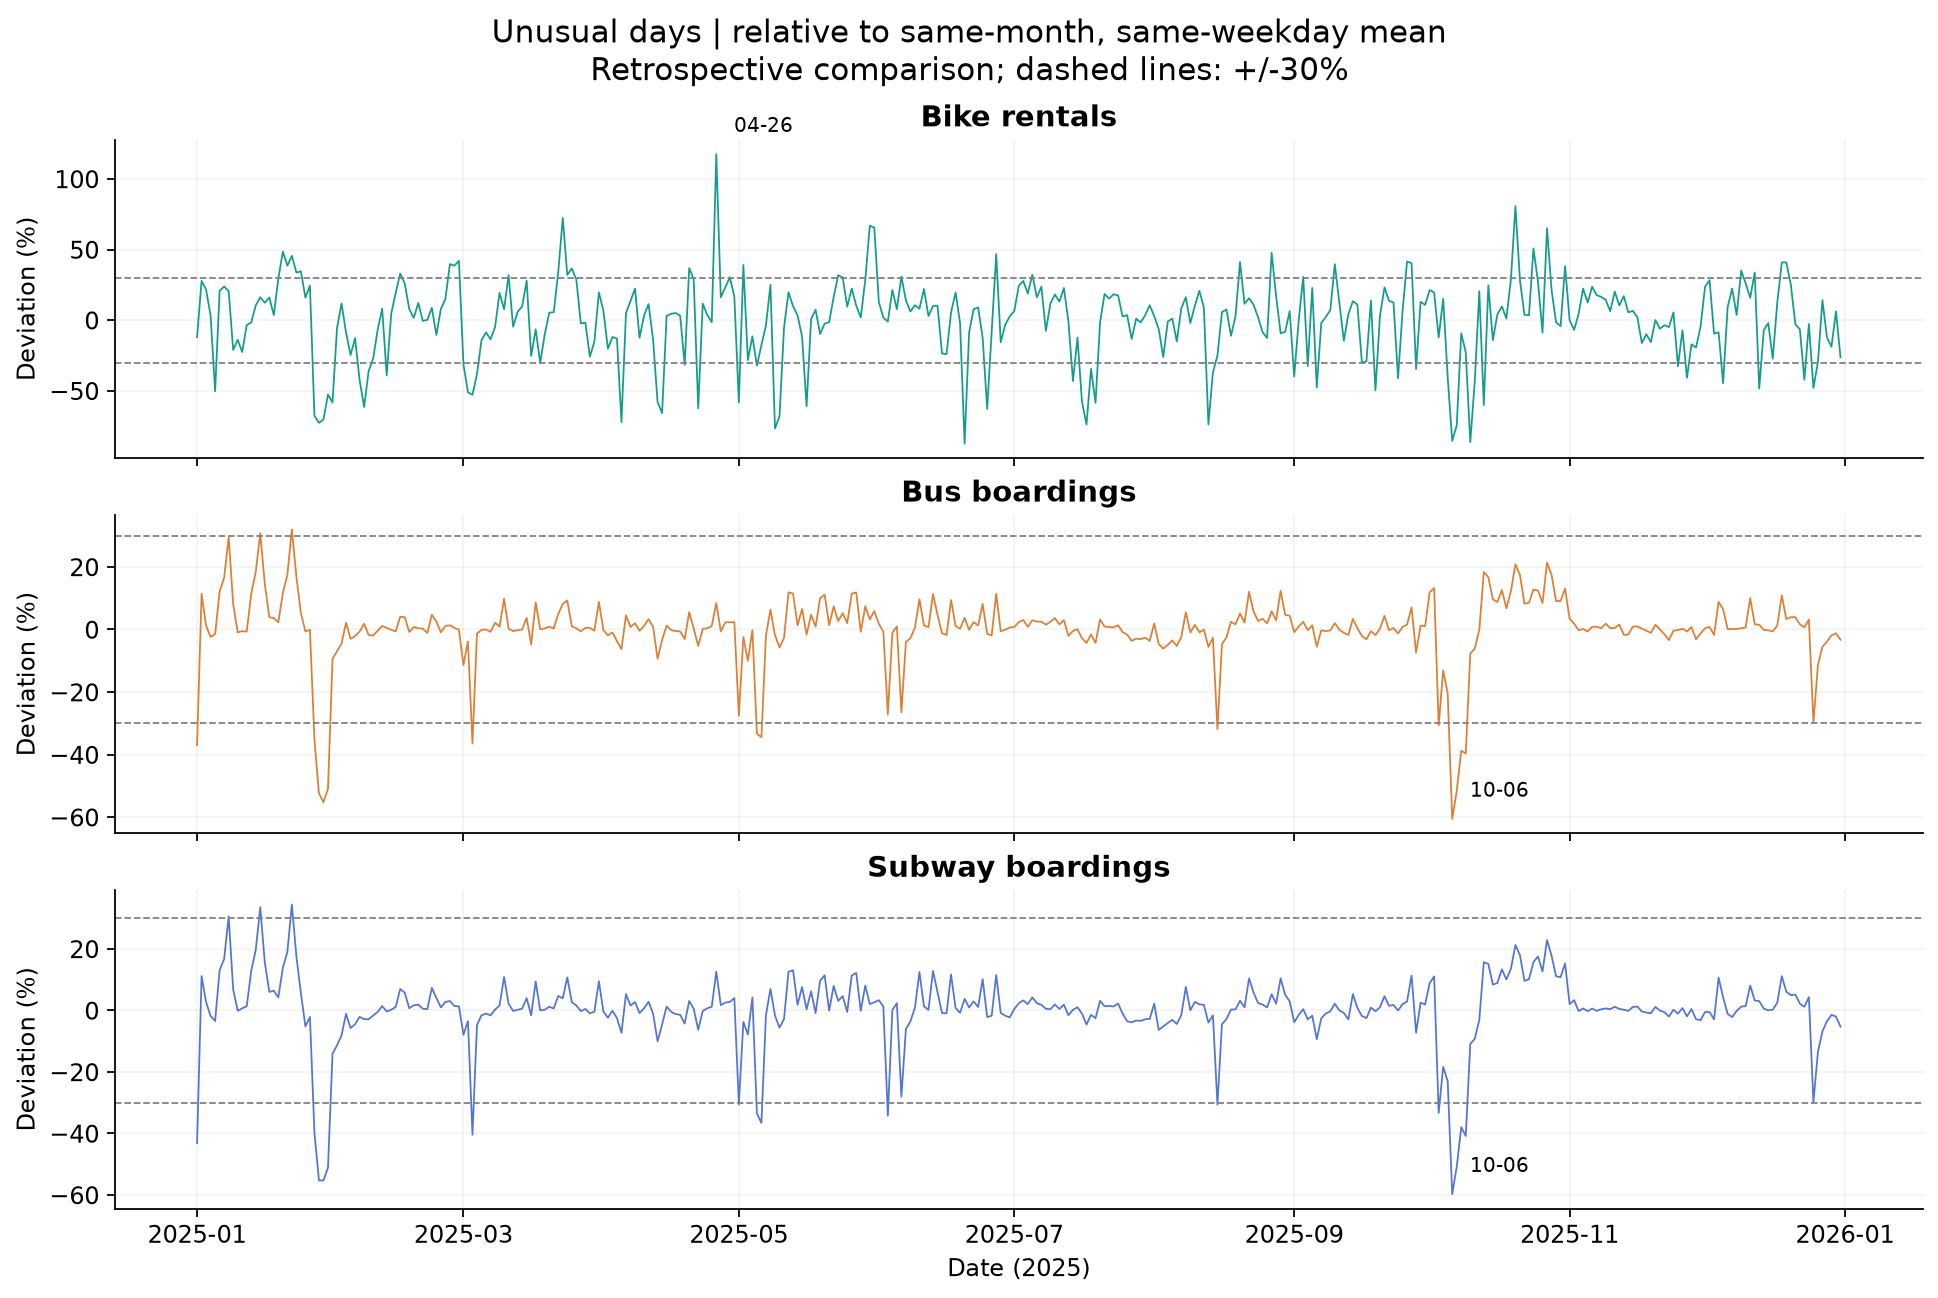

**세 수단 공동 감소 날짜: 13일**

2025-01-27, 2025-01-28, 2025-01-29, 2025-01-30, 2025-03-03, 2025-05-01, 2025-05-05, 2025-08-15, 2025-10-05, 2025-10-06, 2025-10-07, 2025-10-09, 2025-12-25

In [8]:
unusual_rows = []
for mode, s in stats["modes"].items():
    for row in s["top_unusual"][:3]:
        unusual_rows.append(
            {
                "수단": NAMES[mode],
                "날짜": row["date"],
                "실제 건수": row["value"],
                "월×요일 평균": row["baseline"],
                "편차(%)": row["deviation_pct"],
            }
        )
unusual_table = pd.DataFrame(unusual_rows)
display(
    unusual_table.style.hide(axis="index").format(
        {"실제 건수": "{:,.0f}", "월×요일 평균": "{:,.1f}", "편차(%)": "{:+.2f}"}
    )
)
display(Image(filename=str(FIGURES / "04_unusual_days.png")))
display(
    Markdown(
        f"**세 수단 공동 감소 날짜: {len(stats['joint_low_days'])}일**\n\n"
        + ", ".join(stats["joint_low_days"])
    )
)

## 6. 인사이트와 해석의 한계

다음 내용은 같은 계산값으로 생성한 제출 리포트의 인사이트다. 관찰된 수치와 원인에 대한 가설을 구분해서 읽는다.

In [9]:
report_text = render_report(stats, quality, sources, manifest)
insights = report_text.split("## 4. 인사이트: 질문에 대한 답", 1)[1].split("## 5. 결론과 한계", 1)[
    0
]
display(Markdown(insights))



### 인사이트 1. 평일·주말 차이는 수단별로 다르다

| 수단 | 평일 일평균(건) | 주말 일평균(건) | 평일 대비 주말 증감률 |
|---|---:|---:|---:|
| 따릉이 | 109,668.4 | 84,131.0 | -23.29% |
| 서울버스 | 5,089,088.2 | 3,513,022.1 | -30.97% |
| 공개 지하철 | 7,678,456.6 | 5,260,810.5 | -31.49% |

**관찰:** 주말 감소율이 가장 큰 수단은 공개 지하철이며, 감소율은 -31.49%다(그림 2). **활용:** 수단별 주중·주말 수요 수준을 따로 고려할 근거다. 통근·관광 목적의 차이라는 해석은 개인 목적 자료가 없어 가설로 남긴다.

### 인사이트 2. 월별 수요 변동의 크기를 구분할 수 있다

| 수단 | 최고 월·일평균(건) | 최저 월·일평균(건) | 최고/최저 배율 |
|---|---:|---:|---:|
| 따릉이 | 6월 · 134,143.8 | 1월 · 54,978.6 | 2.44배 |
| 서울버스 | 9월 · 5,020,319.5 | 1월 · 3,983,634.6 | 1.26배 |
| 공개 지하철 | 4월 · 7,459,567.3 | 1월 · 6,059,066.3 | 1.23배 |

**관찰:** 월별 일평균의 최고/최저 배율은 따릉이가 가장 크다(2.44배, 그림 1·3). **활용:** 월별 운영 수요를 점검할 우선순위를 제공한다. 1년의 관측만으로 매년 반복되는 계절성이나 날씨의 원인 효과를 확정할 수 없다.

### 인사이트 3. 평소와 크게 다른 날짜를 후속 조사 대상으로 찾을 수 있다

| 수단 | 절대 편차가 가장 큰 날짜 | 실제 건수 | 같은 월·요일 평균 | 편차 |
|---|---|---:|---:|---:|
| 따릉이 | 2025-04-26 | 133,576 | 61,411.0 | +117.51% |
| 서울버스 | 2025-10-06 | 1,710,929 | 4,339,064.0 | -60.57% |
| 공개 지하철 | 2025-10-06 | 2,634,043 | 6,546,247.8 | -59.76% |

**관찰:** 세 수단이 동시에 각자의 월×요일 평균보다 20% 이상 낮았던 날짜는 **13일**이다. 날짜: 2025-01-27, 2025-01-28, 2025-01-29, 2025-01-30, 2025-03-03, 2025-05-01, 2025-05-05, 2025-08-15, 2025-10-05, 2025-10-06, 2025-10-07, 2025-10-09, 2025-12-25(그림 4). 이 20%는 세 수단 공동 감소를 살피는 별도 탐색 기준이며 그림의 ±30% 기준과 구분한다.

**활용:** 휴일·운행 변화·행사·자료 오류 등을 확인할 날짜 목록으로 쓸 수 있다. 여기서는 외부 원인 자료를 결합하지 않았으므로 특정 사건 때문에 감소했다고 결론짓지 않는다.



## 7. 실제 실행 검증

셀을 위에서부터 다시 실행했을 때도 제출 통계·정제본이 같아야 한다. 실행 오류를 무시하는 설정은 사용하지 않는다.

In [10]:
saved_data = pd.read_csv(ROOT / "data/processed/observations.csv", keep_default_na=False)
recomputed = data.copy()
recomputed["date"] = recomputed["date"].dt.strftime("%Y-%m-%d")
assert_frame_equal(recomputed.reset_index(drop=True), saved_data, check_dtype=False)
assert stats == saved_stats
assert len(data) == 1095 and data.groupby("mode").size().eq(365).all()
print("PASS · 실제 데이터 1,095행 전수 일치")
print("PASS · 수단별 365일, 날짜·값 누락 없음")
print("PASS · 노트북 계산과 제출 statistics.json 전체 일치")
print("PASS · 그래프 4개를 현재 계산값으로 생성")

PASS · 실제 데이터 1,095행 전수 일치
PASS · 수단별 365일, 날짜·값 누락 없음
PASS · 노트북 계산과 제출 statistics.json 전체 일치
PASS · 그래프 4개를 현재 계산값으로 생성


### 결론을 사용할 때

- 자료마다 서비스 범위가 다르며 서울 밖 역·정류장이 포함될 수 있다.
- 반복 승차·환승을 제거한 사람 수가 아니고, 세 수단을 더한 값도 고유 인구가 아니다.
- 날씨·휴일·운행 변화·공급량을 통제하지 않았으므로 대체·환승 효과나 감소 원인을 단정할 수 없다.
- 2025년 한 해의 월별 변화이며, 매년 반복되는 계절성은 여러 해로 검증해야 한다.
- 지역·시간대 분석과 예측은 이번 노트북의 범위에 포함하지 않았다.

**공식 출처:** [따릉이](https://data.seoul.go.kr/dataList/OA-14994/F/1/datasetView.do) · [서울버스](https://data.seoul.go.kr/dataList/OA-12912/S/1/datasetView.do) · [지하철](https://data.seoul.go.kr/dataList/OA-12914/F/1/datasetView.do)  
출처: 서울특별시 열린데이터광장, 공공누리 제1유형(출처표시).